In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stas

In [8]:
from src.utils.snapshot import latest_snapshot, processed_dir
from src.analytics.demografia import Demografia

In [9]:
SNAPSHOT = latest_snapshot()
df = pd.read_parquet(processed_dir(SNAPSHOT) / 'fide_players_all.parquet')
df_colombia = df[df['country'] == "COL"]
df_colombia.info()

<class 'pandas.DataFrame'>
Index: 8649 entries, 1404 to 782033
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   fideid          8649 non-null   str     
 1   name            8649 non-null   str     
 2   country         8649 non-null   str     
 3   sex             8649 non-null   str     
 4   title           8649 non-null   category
 5   o_title         8649 non-null   str     
 6   rating          4898 non-null   Int16   
 7   games           8649 non-null   int16   
 8   rapid_rating    6157 non-null   Int16   
 9   rapid_games     8649 non-null   int16   
 10  blitz_rating    5523 non-null   Int16   
 11  blitz_games     8649 non-null   int16   
 12  birthday        8649 non-null   int16   
 13  snapshot_date   8649 non-null   object  
 14  total_games     8649 non-null   int16   
 15  activo_mes      8649 non-null   bool    
 16  activo_fide     8649 non-null   bool    
 17  edad            8649 non-

In [10]:
df_colombia.describe().T

,count,mean,std,min,25%,50%,75%,max
rating,4898.0,1767.718252,195.439523,1400.0,1617.0,1761.0,1902.0,2493.0
games,8649.0,0.098508,1.108899,0.0,0.0,0.0,0.0,30.0
rapid_rating,6157.0,1727.286341,182.495544,1400.0,1585.0,1713.0,1851.0,2513.0
rapid_games,8649.0,0.633599,2.339528,0.0,0.0,0.0,0.0,36.0
blitz_rating,5523.0,1735.573058,187.053989,1400.0,1590.0,1723.0,1861.0,2558.0
blitz_games,8649.0,0.488958,2.970235,0.0,0.0,0.0,0.0,68.0
birthday,8649.0,1991.588739,17.855074,1932.0,1980.0,1996.0,2006.0,2021.0
total_games,8649.0,1.221066,4.233573,0.0,0.0,0.0,0.0,68.0
edad,8649.0,34.411261,17.855074,5.0,20.0,30.0,46.0,94.0


## Analisis demografico

In [11]:
fed = Demografia(df, "COL")
resumen = fed.kpis_demograficos()

df_resumen = fed.kpis_demograficos()
df_resumen


,cantidad,porcentaje
indicador,,
registrados,8649,100.00
hombres,7640,88.30
mujeres,1009,11.70
juveniles,2314,26.80
adultos,6335,73.20
mujeres_juveniles,411,17.80
mujeres_adultas,598,9.40
titulados,336,3.88
sin_titulo,8313,96.12


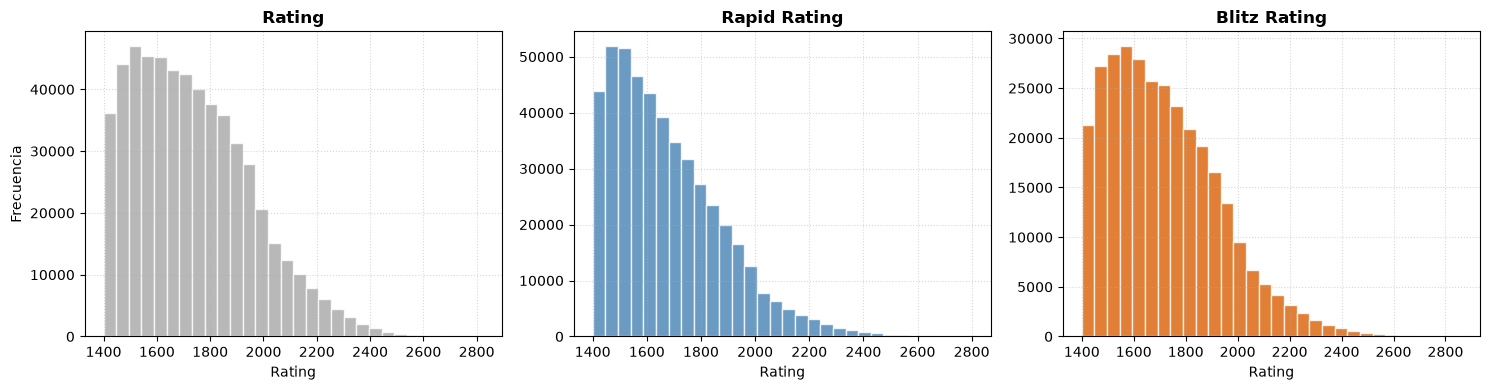

In [12]:
modalidades = [
    'rating',
    'rapid_rating',
    'blitz_rating',
]
colores = ["#A6A6A6", "steelblue", "#D95F02"]

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), sharey=False)

for i, col in enumerate(modalidades): 
    ax[i].hist(df[col], bins=30, color=colores[i], edgecolor="white", alpha=0.8)
    ax[i].set_title(col.replace("_", " ").title(), fontsize=12, fontweight="bold")
    ax[i].set_xlabel("Rating")
    ax[i].set_ylabel("Frecuencia" if i == 0 else "")
    ax[i].grid(True, linestyle=":", alpha=0.5)

fig.tight_layout()
plt.show()
    


In [13]:
df_elos = df_colombia[['rating', 'rapid_rating', "blitz_rating"]]
df_elos.median().T

rating          1761.0
rapid_rating    1713.0
blitz_rating    1723.0
dtype: Float64